# ICE 4112 Artificial Intelligence Lab Quiz
## Image Classification using the Olivetti Faces Dataset and MobileNetV2

**Objective:** Build a face-identity classification system using transfer learning. This notebook covers all five required parts: data preparation, model implementation, model training, performance evaluation, and result analysis.

**Dataset:** Olivetti Faces (400 grayscale images, 40 people, 10 images per person). The dataset is downloaded automatically through scikit-learn.  
**Framework:** TensorFlow / Keras  
**Important:** Run the cells from top to bottom in Google Colab. Select **Runtime → Change runtime type → T4 GPU** if available; CPU also works but may be slower.

### 1. Import libraries

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: []


### 2. Data Preparation (Question 1)
Load the Olivetti Faces dataset, inspect its dimensions, create a stratified train/test split, resize images, and convert grayscale images to RGB for the pretrained model.

In [2]:
faces = fetch_olivetti_faces(shuffle=True, random_state=SEED)
X = faces.images                  # shape: (400, 64, 64), pixel values in [0, 1]
y = faces.target.astype("int32")  # 40 identity classes: 0 to 39

class_names = [f"Person {i:02d}" for i in range(40)]
print("Images:", X.shape)
print("Labels:", y.shape)
print("Number of people/classes:", len(np.unique(y)))
print("Pixel range:", X.min(), "to", X.max())

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Images: (400, 64, 64)
Labels: (400,)
Number of people/classes: 40
Pixel range: 0.0 to 1.0


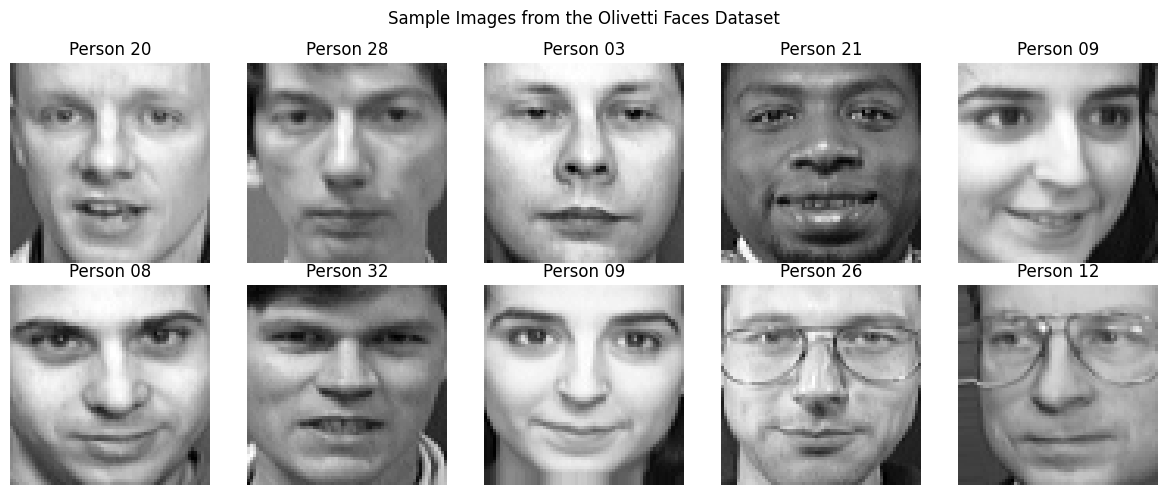

In [3]:
# Display sample images
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i], cmap="gray")
    plt.title(class_names[y[i]])
    plt.axis("off")
plt.suptitle("Sample Images from the Olivetti Faces Dataset")
plt.tight_layout()
plt.show()

In [4]:
# Stratified split keeps examples from every identity in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

IMG_SIZE = 96

def prepare_images(images):
    # Convert 64x64 grayscale images to 96x96 RGB images.
    images = images[..., np.newaxis]
    images = tf.image.resize(images, (IMG_SIZE, IMG_SIZE)).numpy()
    images = np.repeat(images, 3, axis=-1)
    # Dataset pixels are [0,1]; convert to [0,255], then apply MobileNetV2 preprocessing.
    images = images * 255.0
    return preprocess_input(images.astype("float32"))

X_train_ready = prepare_images(X_train)
X_test_ready = prepare_images(X_test)

NUM_CLASSES = len(np.unique(y))
print("Training images:", X_train_ready.shape)
print("Testing images:", X_test_ready.shape)
print("Training labels:", y_train.shape, "| Test labels:", y_test.shape)

Training images: (320, 96, 96, 3)
Testing images: (80, 96, 96, 3)
Training labels: (320,) | Test labels: (80,)


### 3. Model Implementation (Question 2)
Use ImageNet-pretrained MobileNetV2 as a frozen feature extractor and replace its classification head with a 40-class output layer. Data augmentation and dropout help reduce overfitting.

In [5]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomZoom(0.05),
], name="data_augmentation")

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.40)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = models.Model(inputs, outputs, name="Olivetti_MobileNetV2")
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Olivetti_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │         5,160 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,427,112 (9.26 MB)

 Trainable params: 169,128 (660.66 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 4. Model Training (Question 3)
Train the new classification head. Early stopping and learning-rate reduction are used to help control overfitting. The validation set is taken from the training data; the test set remains untouched until final evaluation.

In [6]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_ready, y_train, test_size=0.20,
    random_state=SEED, stratify=y_train
)

callbacks = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1)
]

history = model.fit(
    X_fit, y_fit,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=16,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 20s 423ms/step - accuracy: 0.0312 - loss: 4.4083 - val_accuracy: 0.0938 - val_loss: 3.5384 - learning_rate: 0.0010
Epoch 2/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 186ms/step - accuracy: 0.0859 - loss: 3.5708 - val_accuracy: 0.1875 - val_loss: 3.3702 - learning_rate: 0.0010
Epoch 3/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 161ms/step - accuracy: 0.1562 - loss: 3.3317 - val_accuracy: 0.2188 - val_loss: 3.2055 - learning_rate: 0.0010
Epoch 4/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 241ms/step - accuracy: 0.1797 - loss: 3.1103 - val_accuracy: 0.3125 - val_loss: 2.9546 - learning_rate: 0.0010
Epoch 5/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 185ms/step - accuracy: 0.2695 - loss: 2.7573 - val_accuracy: 0.2656 - val_loss: 2.7773 - learning_rate: 0.0010
Epoch 6/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 174ms/step - accuracy: 0.3438 - loss: 2.4911 - val_accuracy: 0.3438 - val_loss: 2.4164 - learning_rate: 0.0010
Epoch 7/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 179ms/step - accuracy: 0.3594 - loss: 2.2926 -

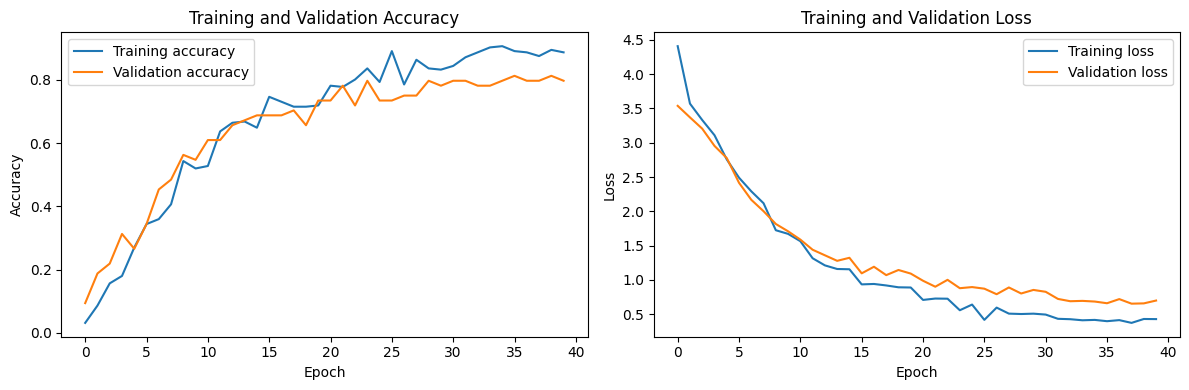

In [7]:
# Plot training history
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

### 5. Performance Evaluation (Question 4)
Evaluate the final model on the held-out test set. The notebook reports accuracy, macro-averaged precision, recall, F1-score, a per-class report, and a confusion matrix.

In [8]:
test_loss, test_accuracy = model.evaluate(X_test_ready, y_test, verbose=0)
y_prob = model.predict(X_test_ready, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

print(f"Test Loss       : {test_loss:.4f}")
print(f"Test Accuracy   : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Macro Precision : {precision:.4f}")
print(f"Macro Recall    : {recall:.4f}")
print(f"Macro F1-score  : {f1:.4f}")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, labels=np.arange(NUM_CLASSES),
    target_names=class_names, zero_division=0
))

Test Loss       : 0.5430
Test Accuracy   : 0.8500 (85.00%)
Macro Precision : 0.8642
Macro Recall    : 0.8500
Macro F1-score  : 0.8293

Classification Report:
              precision    recall  f1-score   support

   Person 00       0.67      1.00      0.80         2
   Person 01       0.50      1.00      0.67         2
   Person 02       1.00      1.00      1.00         2
   Person 03       1.00      1.00      1.00         2
   Person 04       1.00      1.00      1.00         2
   Person 05       1.00      1.00      1.00         2
   Person 06       1.00      0.50      0.67         2
   Person 07       1.00      1.00      1.00         2
   Person 08       0.67      1.00      0.80         2
   Person 09       1.00      1.00      1.00         2
   Person 10       0.67      1.00      0.80         2
   Person 11       1.00      1.00      1.00         2
   Person 12       1.00      0.50      0.67         2
   Person 13       1.00      1.00      1.00         2
   Person 14       1.00      1.

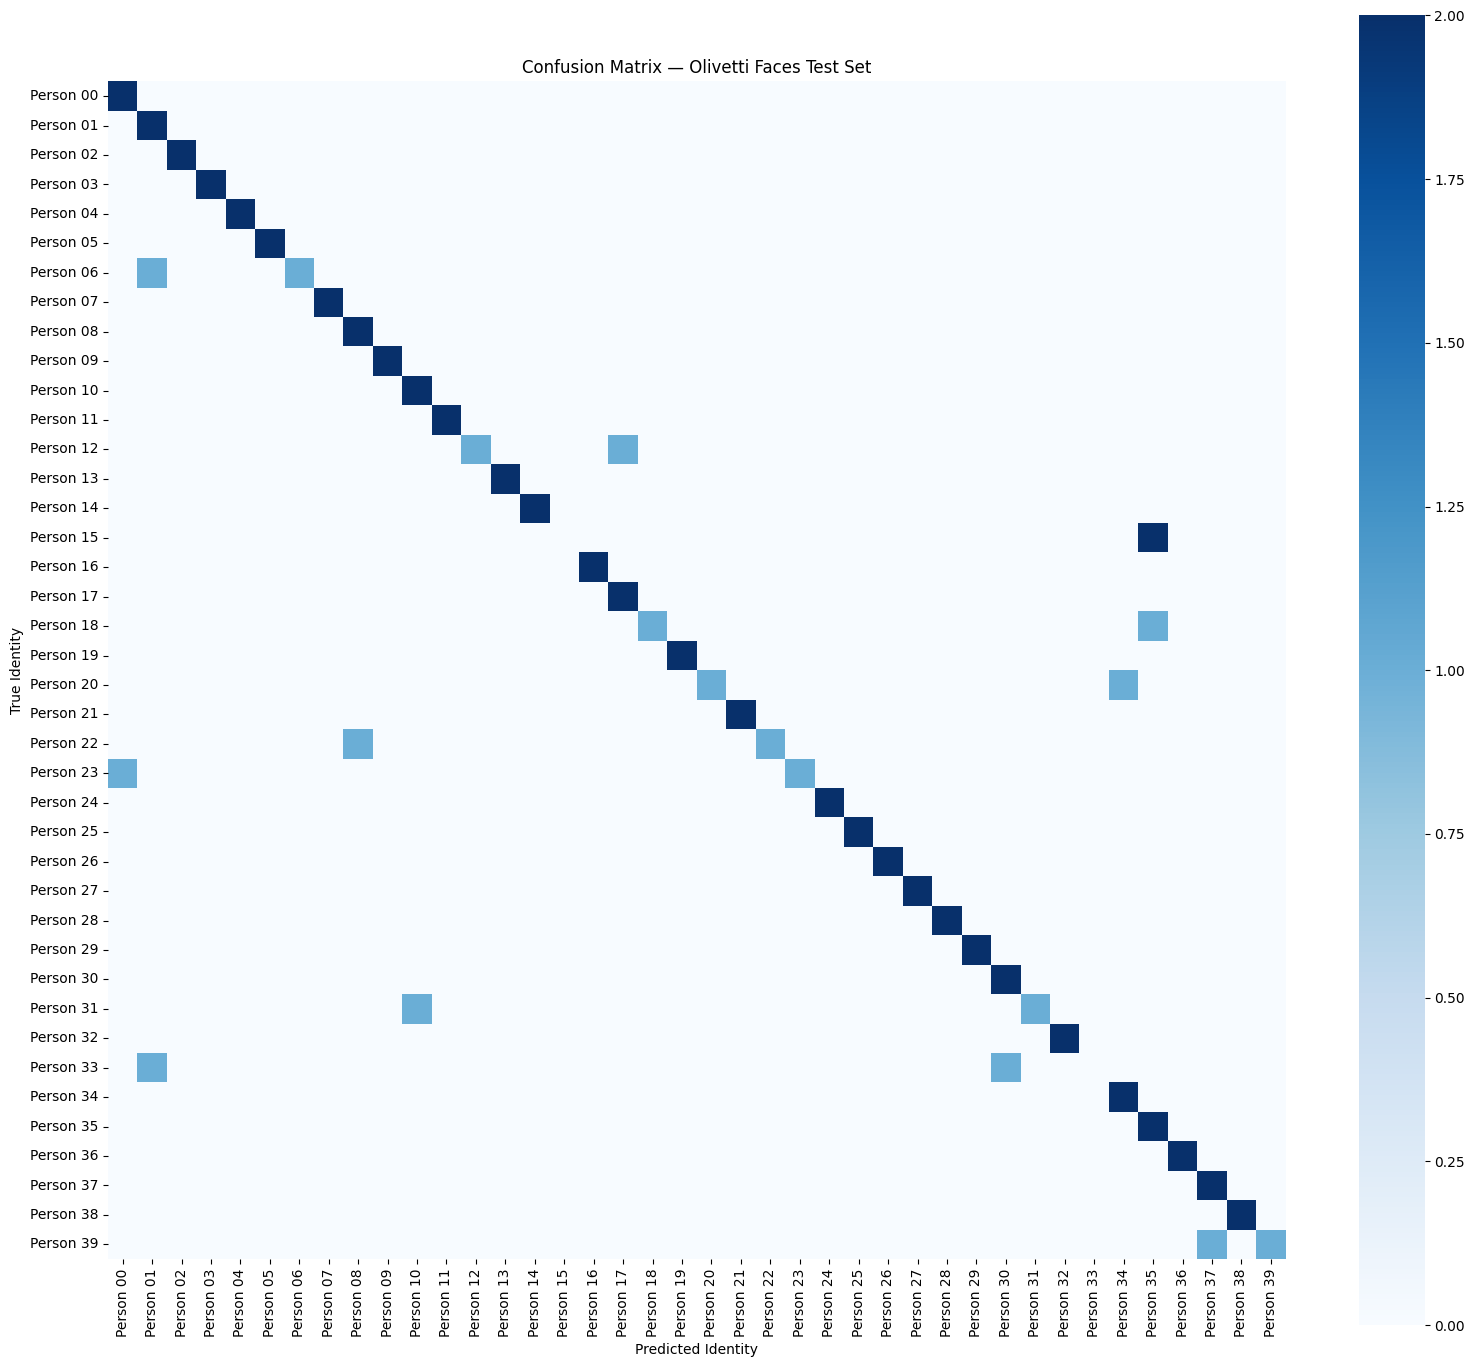

In [9]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(NUM_CLASSES))
plt.figure(figsize=(16, 14))
sns.heatmap(cm, cmap="Blues", annot=False, square=True,
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix — Olivetti Faces Test Set")
plt.xlabel("Predicted Identity")
plt.ylabel("True Identity")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 6. Result Analysis (Question 5)
The cell below creates a short result summary automatically using the metrics from the test set. Interpret the actual output after running the notebook; do not report expected or assumed scores as measured results.

In [10]:
print("RESULT ANALYSIS")
print("-" * 60)
print(f"The MobileNetV2 transfer-learning model achieved {accuracy*100:.2f}% test accuracy.")
print(f"Macro precision = {precision:.4f}, macro recall = {recall:.4f}, and macro F1-score = {f1:.4f}.")
print(f"The test set contains {len(y_test)} images from {NUM_CLASSES} identity classes.")

if accuracy >= 0.90:
    print("The result indicates strong overall identity classification on this held-out split.")
elif accuracy >= 0.70:
    print("The model learned useful identity features, but some people may be confused with others.")
else:
    print("Performance is limited. Consider training longer, adjusting augmentation, or fine-tuning a small part of the backbone.")

print("Use the confusion matrix and per-class report to identify which identities are most often confused.")
print("Limitation: Olivetti Faces is a small, controlled dataset; results may not generalize to real-world face images.")

RESULT ANALYSIS
------------------------------------------------------------
The MobileNetV2 transfer-learning model achieved 85.00% test accuracy.
Macro precision = 0.8642, macro recall = 0.8500, and macro F1-score = 0.8293.
The test set contains 80 images from 40 identity classes.
The model learned useful identity features, but some people may be confused with others.
Use the confusion matrix and per-class report to identify which identities are most often confused.
Limitation: Olivetti Faces is a small, controlled dataset; results may not generalize to real-world face images.


### Conclusion
This notebook implements all five quiz requirements using the Olivetti Faces dataset and a pretrained MobileNetV2 model. It prepares and visualizes the data, adapts a pretrained network to 40 identity classes, trains with overfitting controls, evaluates with accuracy/precision/recall/F1 and a confusion matrix, and prints a result analysis.

**Submission note:** Run every cell in Google Colab and submit the executed notebook with the actual metrics and plots. Scores may vary slightly by runtime and training behavior.